# Messi vs CR7 — Fase 2B: regresión de Poisson bayesiana (PyMC)

**Requisito:** haber ejecutado `02_modelo_series_temporales.ipynb`, que genera `modelo_base.csv` y `parametros_modelo.json`.

El modelo A tenía dos debilidades:
1. trataba la tasa de gol como **conocida**,
2. **no sabe que los jugadores envejecen**, y por eso sobreestimaba en el backtest.

El modelo bayesiano corrige ambas cosas.

### El modelo

Para cada jugador y año $t$:

$$\text{goles}_t \sim \text{Poisson}\!\left(\lambda_t \cdot \frac{\text{expo}_t}{c_t^{\gamma}}\right)$$

$$\lambda_t \sim \text{Gamma}\!\left(\text{media}=\mu_t,\ \ \text{varianza}=\frac{\mu_t^2\,\tau^2}{w_t}\right)$$

$$\log \mu_t = \theta + \beta\,(\text{edad}_t - \text{edad}_{\text{hoy}})$$

- $\lambda_t$ es el nivel goleador **ajustado por liga** de ese año. $\text{expo}_t / c_t^{\gamma}$ lo convierte en goles reales esperados (igual que en el modelo A).
- $\theta$ es el log del nivel **hoy**. $\beta$ es la **pendiente de envejecimiento**: $e^{\beta}-1$ = % de cambio por cada año de edad.
- **Aquí entran los pesos.** El prior de cada año tiene varianza $\propto 1/w_t$. Un año reciente ($w \approx 1$) queda "amarrado" a la curva $\mu_t$ y la define. Un año viejo ($w \approx 0$) tiene un prior tan ancho que puede desviarse casi libremente y casi no influye en $\theta$ ni en $\beta$. Así los pesos dinámicos **modulan la varianza de los priors** y le dan prioridad al rendimiento actual.

Un detalle matemático útil: si integramos $\lambda_t$ (Gamma) dentro del Poisson, se obtiene una **Binomial Negativa** con dispersión $\alpha_t = w_t/\tau^2$. Así lo escribimos en PyMC, porque es más eficiente para el muestreador.

### Priors

| Parámetro | Prior | Justificación |
|---|---|---|
| $\theta$ | $\mathcal{N}(\log 35,\ 0.5)$ | ~35 goles ajustados/año, con margen amplio (entre 13 y 93 al 95%) |
| $\beta$ | $\mathcal{N}(-0.05,\ 0.05)$ | A los 39–41 años lo esperable es una caída de algunos % por año, pero se permite que los datos digan otra cosa |
| $\tau$ | $\text{HalfNormal}(0.3)$ | Variación de un año a otro más allá del azar de Poisson |

In [14]:
%pip install pymc

Note: you may need to restart the kernel to use updated packages.


La celda anterior solo hace falta la primera vez. Si al importar PyMC aparece un aviso de `g++` o de compilador, puedes ignorarlo: el modelo es pequeño y corre igual, solo más lento.

In [15]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

RUTA = Path(r"C:\Users\DANIEL\OneDrive\Escritorio\Messi vs Cristiano")
DATA = RUTA / "data_limpia"

base = pd.read_csv(DATA / "modelo_base.csv", parse_dates=["mitad", "fin"])
P = json.loads((DATA / "parametros_modelo.json").read_text(encoding="utf-8"))

JUG = ["Messi", "Ronaldo"]
COLORES = {"Messi": "#2a78d6", "Ronaldo": "#eb6834"}
CORTE    = {j: pd.Timestamp(P["corte"][j]) for j in JUG}
CONTRATO = {j: pd.Timestamp(P["contrato"][j]) for j in JUG}
edad_hoy = {j: (CORTE[j] - pd.Timestamp(P["nacimiento"][j])).days / 365.25 for j in JUG}

print("H =", P["H"], "| gamma =", P["gamma"], "| edad al corte:", {j: round(e, 1) for j, e in edad_hoy.items()})

H = 0.75 | gamma = 1.0 | edad al corte: {'Messi': 39.2, 'Ronaldo': 41.5}


### Datos en formato de arrays

PyMC trabaja con arrays de numpy. `idx` le dice a cada fila a qué jugador pertenece (0 = Messi, 1 = Ronaldo), de modo que `theta[idx]` repite el parámetro correcto en cada fila. `offset` es la parte conocida del log de la media (exposición y liga), así que no se estima.

**Años con peso casi nulo.** Un año con $w < 0.005$ tendría un prior más de 200 veces más ancho que el del año actual, así que no aporta información. Pero tampoco es inocuo dejarlo con un "piso" de peso. Lo probé: con un piso, el $\tau$ estimado cambiaba según el piso elegido, porque esos ~15 años viejos terminaban determinando la varianza de todo el modelo. Que un parámetro dependa de una decisión arbitraria es señal de mala especificación. La solución limpia es **dejar fuera los años con $w <$ `W_MIN`**: así el modelo aprende de 2021 en adelante (de los 34 a los 41 años de Ronaldo y de los 34 a los 39 de Messi), que es justamente la etapa de envejecimiento que queremos medir.

In [16]:
W_MIN = 0.005
mod = base[base.w >= W_MIN].reset_index(drop=True)

idx = mod.jugador.map({"Messi": 0, "Ronaldo": 1}).values
edad_rel = (mod.edad - mod.jugador.map(edad_hoy)).values
offset = np.log(mod.expo.values) - P["gamma"] * np.log(mod.coef_mix.values)
w = mod.w.values
y = mod.goles.values

mod.assign(edad_rel=edad_rel)[["jugador", "anio", "goles", "coef_mix", "expo", "edad_rel", "w"]].round(3)

,jugador,anio,goles,coef_mix,expo,edad_rel,w
0,Messi,2021,43,0.981,1.000,-5.218,0.007
1,Messi,2022,35,0.864,1.000,-4.219,0.018
2,Messi,2023,28,0.762,1.000,-3.220,0.046
3,Messi,2024,29,0.717,1.000,-2.220,0.116
4,Messi,2025,46,0.709,1.000,-1.218,0.292
5,Messi,2026,34,0.776,0.721,-0.359,0.646
6,Ronaldo,2021,47,0.930,1.000,-5.133,0.008
7,Ronaldo,2022,16,0.950,1.000,-4.134,0.020
8,Ronaldo,2023,54,0.675,1.000,-3.135,0.050
9,Ronaldo,2024,43,0.652,1.000,-2.136,0.125


In [17]:
coords = {"jugador": JUG, "obs": np.arange(len(y))}

with pm.Model(coords=coords) as modelo:
    theta = pm.Normal("theta", mu=np.log(35), sigma=0.5, dims="jugador")
    beta  = pm.Normal("beta", mu=-0.05, sigma=0.05, dims="jugador")
    tau   = pm.HalfNormal("tau", sigma=0.3)

    mu = pm.math.exp(theta[idx] + beta[idx] * edad_rel + offset)
    pm.NegativeBinomial("goles", mu=mu, alpha=tau**-2 * w, observed=y, dims="obs")

    idata = pm.sample(draws=2000, tune=1500, chains=4, cores=1, target_accept=0.9, random_seed=7)

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [theta, beta, tau]


Output()

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 8 seconds.


`cores=1` corre las 4 cadenas una detrás de otra. En Windows esto evita problemas de multiprocesamiento dentro de Jupyter, y con un modelo tan pequeño la diferencia de tiempo es mínima.

### Diagnóstico: 

Antes de mirar resultados hay que revisar tres cosas:
- **`r_hat` ≈ 1.00** (menor a 1.01): las 4 cadenas llegaron al mismo lugar.
- **`ess_bulk` y `ess_tail` > 400**: hay suficientes muestras "independientes".
- **0 divergencias**: el muestreador no encontró zonas problemáticas.

In [18]:
print("Divergencias:", int(idata.sample_stats["diverging"].sum()))
az.summary(idata, var_names=["theta", "beta", "tau"], ci_prob=0.9, ci_kind="hdi")

Divergencias: 0


,mean,sd,hdi90_lb,hdi90_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta[Messi],3.386,0.129,3.2,3.6,7815,6074,1.00,0.0015,0.0015
theta[Ronaldo],3.229,0.128,3,3.4,6880,6077,1.00,0.0015,0.0014
beta[Messi],-0.0128,0.0424,-0.085,0.052,7399,6246,1.00,0.00049,0.00046
beta[Ronaldo],-0.051,0.0428,-0.12,0.019,6583,5837,1.00,0.00053,0.00047
tau,0.0572,0.0233,0.021,0.092,6583,4751,1.00,0.00028,0.00037


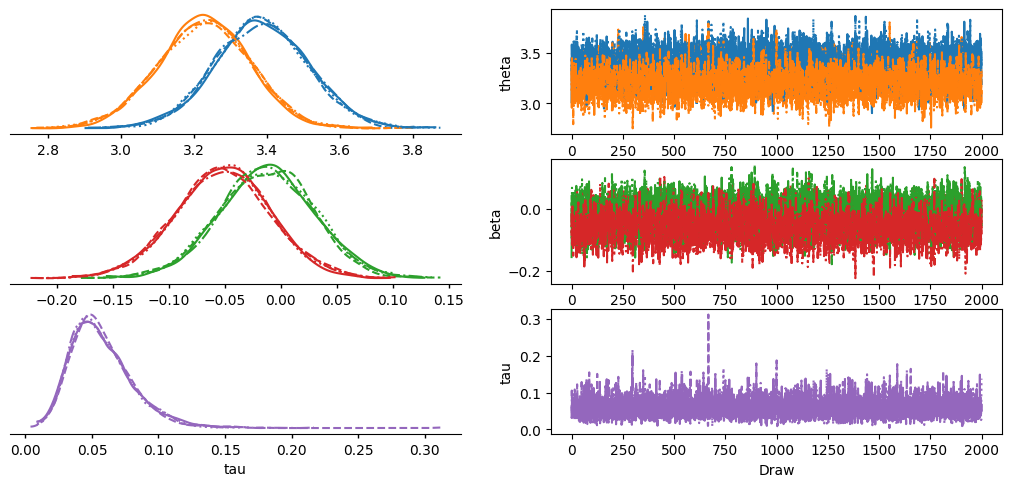

In [19]:
az.plot_trace_dist(idata, var_names=["theta", "beta", "tau"], compact=True)
plt.show()

En el trace plot, la columna izquierda debe mostrar curvas suaves que coinciden entre cadenas y la derecha debe parecer "ruido blanco" sin tendencias.

### Interpretación en unidades que se entienden

In [20]:
post = idata.posterior
theta_s = post["theta"].values.reshape(-1, 2)
beta_s  = post["beta"].values.reshape(-1, 2)
tau_s   = post["tau"].values.ravel()
S = len(tau_s)

interp = pd.DataFrame({
    "goles_aj_año (hoy)": np.exp(theta_s).mean(0),
    "goles_reales_año (hoy)": (np.exp(theta_s) / np.array([P["c_futuro"][j] for j in JUG])).mean(0),
    "cambio_por_año_edad_%": (np.exp(beta_s) - 1).mean(0) * 100,
    "P(declive)": (beta_s < 0).mean(0),
}, index=JUG)
print(f"tau (variación año a año): {tau_s.mean():.3f}   | muestras: {S}")
interp.round(2)

tau (variación año a año): 0.057   | muestras: 8000


,goles_aj_año (hoy),goles_reales_año (hoy),cambio_por_año_edad_%,P(declive)
Messi,29.79,40.40,-1.18,0.62
Ronaldo,25.45,37.39,-4.93,0.89


- **goles_reales_año**: el ritmo actual traducido a goles reales en su contexto de liga (comparable con el `goles_por_año` del modelo A).
- **cambio_por_año_edad_%**: cuánto se espera que caiga (o suba) ese ritmo por cada año que pasa.
- **P(declive)**: probabilidad posterior de que la pendiente sea negativa.

## Proyección por simulación (Monte Carlo)

Para cada una de las muestras del posterior simulamos el futuro **semana a semana**:
1. cada año calendario futuro recibe un "shock" $\sim \text{Gamma}$ con media 1 y CV $\tau$ (temporadas buenas y malas),
2. el ritmo semanal es $e^{\theta + \beta\,\Delta t}\cdot \text{shock} / c_{\text{futuro}}$,
3. los goles de la semana salen de un Poisson y se acumulan hasta pasar 1000.

Así cada simulación combina las **tres fuentes de incertidumbre**: el parámetro (no conocemos θ ni β exactos), la variación entre temporadas (τ) y el azar del día a día (Poisson).

In [21]:
HASTA = pd.Timestamp("2031-01-01")
rng = np.random.default_rng(7)


def simular(jug, k):
    semanas = pd.date_range(CORTE[jug], HASTA, freq="7D")[1:]
    dt = ((semanas - CORTE[jug]).days / 365.25).values
    n_anio = (semanas.year - semanas.year[0]).values

    shock = rng.gamma(1 / tau_s[:, None]**2, tau_s[:, None]**2, size=(S, n_anio.max() + 1))
    tasa = np.exp(theta_s[:, [k]] + beta_s[:, [k]] * dt) * shock[:, n_anio] / P["c_futuro"][jug]

    acum = P["total"][jug] + rng.poisson(tasa * 7 / 365.25).cumsum(axis=1)
    llego = acum >= 1000
    pos = np.where(llego.any(axis=1), llego.argmax(axis=1), -1)
    fechas = pd.Series(np.where(pos >= 0, semanas.values[pos], np.datetime64("NaT", "ns")))
    return fechas, acum, semanas


sims = {jug: simular(jug, k) for k, jug in enumerate(JUG)}
llegadas = {jug: s[0] for jug, s in sims.items()}

In [22]:
res_b = pd.DataFrame({
    jug: {"p10": f.quantile(.1).date(), "mediana": f.quantile(.5).date(), "p90": f.quantile(.9).date(),
          "P_antes_fin_contrato": (f < CONTRATO[jug]).mean(),
          "P_llega_antes_2031": f.notna().mean()}
    for jug, f in llegadas.items()
}).T

r, m = llegadas["Ronaldo"], llegadas["Messi"]
p_cr7 = (r.notna() & (m.isna() | (r < m))).mean()

print(f"P(Ronaldo llega primero) = {p_cr7:.2%}")
print(f"Ventaja mediana de Ronaldo: {(m - r).median().days / 30.4:.1f} meses\n")
res_b

P(Ronaldo llega primero) = 99.98%
Ventaja mediana de Ronaldo: 14.6 meses



,p10,mediana,p90,P_antes_fin_contrato,P_llega_antes_2031
Messi,2028-02-06,2028-06-25,2028-12-31,0.893875,1.0
Ronaldo,2027-02-04,2027-04-08,2027-07-01,0.886875,1.0


## Comparación de modelos

In [23]:
res_a = pd.read_csv(DATA / "resultados_modelo_a.csv", index_col="jugador")

comp = pd.DataFrame({
    "A_goles_año": res_a.goles_por_año,
    "B_goles_año": interp["goles_reales_año (hoy)"],
    "A_mediana": res_a.mediana,
    "B_mediana": res_b.mediana.astype(str),
    "A_rango80": res_a.p10.str[:7] + " a " + res_a.p90.str[:7],
    "B_rango80": res_b.p10.astype(str).str[:7] + " a " + res_b.p90.astype(str).str[:7],
    "A_P_contrato": res_a.P_antes_fin_contrato,
    "B_P_contrato": res_b.P_antes_fin_contrato.astype(float),
})
comp.round(3)

,A_goles_año,B_goles_año,A_mediana,B_mediana,A_rango80,B_rango80,A_P_contrato,B_P_contrato
Messi,44.261,40.399,2028-04-16,2028-06-25,2028-01 a 2028-07,2028-02 a 2028-12,0.999,0.894
Ronaldo,37.832,37.388,2027-03-27,2027-04-08,2027-02 a 2027-05,2027-02 a 2027-07,0.967,0.887


Qué esperar al comparar:
- El modelo B debería dar fechas **algo más tardías**, por la pendiente de edad, y **rangos más anchos**, porque suma la incertidumbre del parámetro y la variación entre temporadas.
- Si los dos modelos coinciden en quién llega primero, la conclusión es robusta frente a la elección del modelo.

## Visualización

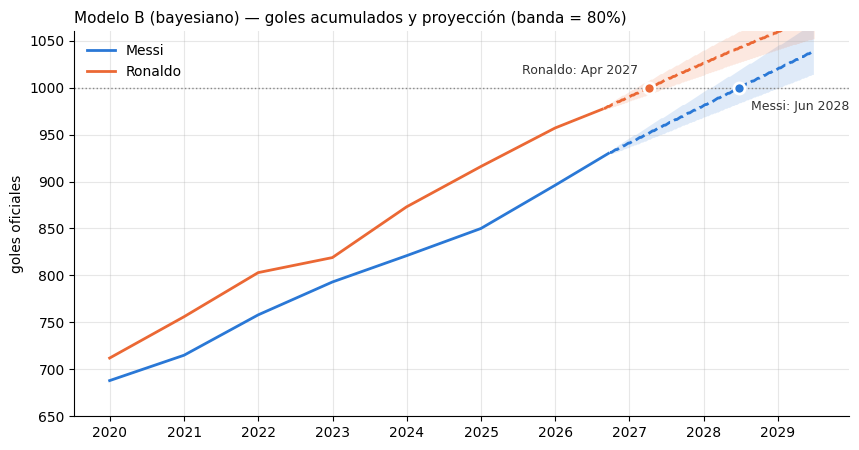

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

for jug in JUG:
    sub = base[(base.jugador == jug) & (base.anio >= 2019)]
    ax.plot(sub.fin, base[base.jugador == jug].goles.cumsum()[sub.index], color=COLORES[jug], lw=2, label=jug)

    _, acum, semanas = sims[jug]
    p10, p50, p90 = np.percentile(acum, [10, 50, 90], axis=0)
    ok = semanas <= pd.Timestamp("2029-06-30")
    ax.fill_between(semanas[ok], p10[ok], p90[ok], color=COLORES[jug], alpha=0.15, lw=0)
    ax.plot(semanas[ok], p50[ok], color=COLORES[jug], lw=2, ls="--")

    med = pd.Timestamp(res_b.loc[jug, "mediana"])
    ax.plot(med, 1000, "o", ms=8, color=COLORES[jug], mec="white", mew=2, zorder=5)
    izq = jug == "Ronaldo"
    ax.annotate(f"{jug}: {med:%b %Y}", (med, 1000), xytext=(-8 if izq else 8, 10 if izq else -16),
                textcoords="offset points", ha="right" if izq else "left", fontsize=9, color="#333")

ax.axhline(1000, color="#888", lw=1, ls=":")
ax.set_ylim(650, 1060)
ax.set_title("Modelo B (bayesiano) — goles acumulados y proyección (banda = 80%)", loc="left", fontsize=11)
ax.set_ylabel("goles oficiales")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

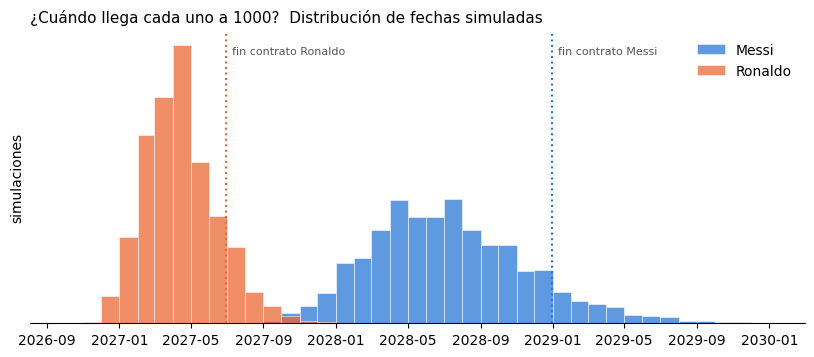

In [25]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = pd.date_range("2026-10-01", "2030-01-01", freq="MS")

for jug in JUG:
    f = llegadas[jug].dropna()
    ax.hist(f, bins=bins, color=COLORES[jug], alpha=0.75, label=jug, edgecolor="white", linewidth=0.5)

for jug in JUG:
    ax.axvline(CONTRATO[jug], color=COLORES[jug], lw=1.5, ls=":")
    ax.annotate(f"fin contrato {jug}", (CONTRATO[jug], ax.get_ylim()[1] * 0.92), xytext=(4, 0),
                textcoords="offset points", fontsize=8, color="#555")

ax.set_title("¿Cuándo llega cada uno a 1000?  Distribución de fechas simuladas", loc="left", fontsize=11)
ax.set_ylabel("simulaciones")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Resultados para el dashboard

In [26]:
filas = []
for jug, (_, acum, semanas) in sims.items():
    q = np.percentile(acum, [10, 50, 90], axis=0)
    filas.append(pd.DataFrame({"jugador": jug, "fecha": semanas, "p10": q[0], "p50": q[1], "p90": q[2]}))
pd.concat(filas).to_csv(DATA / "proyeccion_bayes.csv", index=False)

pd.DataFrame(llegadas).to_csv(DATA / "llegadas_bayes.csv", index=False)
res_b.assign(P_ronaldo_primero=p_cr7).to_csv(DATA / "resultados_modelo_b.csv", index_label="jugador")

sorted(p.name for p in DATA.iterdir())

['cr7_goles_club_limpio.csv',
 'goles_por_anio.csv',
 'llegadas_bayes.csv',
 'messi_goles_limpio.csv',
 'modelo_base.csv',
 'parametros_modelo.json',
 'partidos.csv',
 'proyeccion_bayes.csv',
 'resultados_modelo_a.csv',
 'resultados_modelo_b.csv',
 'resumen_totales.csv']